**Care Transition Efficiency & Placement outcome Analytics**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Display options
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)


In [ ]:
file_path = "/content/HHS_Unaccompanied_Alien_Children_Program.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (1170, 6)


In [ ]:
df.head()

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,"December 21, 2025",6.00,18.00,11.00,"2,484",14.00
1,"December 18, 2025",11.00,50.00,6.00,"2,472",16.00
2,"December 17, 2025",7.00,31.00,11.00,"2,481",10.00
3,"December 16, 2025",8.00,54.00,15.00,"2,468",9.00
4,"December 15, 2025",11.00,42.00,9.00,"2,470",7.00


In [ ]:
df.tail()

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
1165,NaN,NaN,NaN,NaN,NaN,NaN
1166,NaN,NaN,NaN,NaN,NaN,NaN
1167,NaN,NaN,NaN,NaN,NaN,NaN
1168,NaN,NaN,NaN,NaN,NaN,NaN
1169,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.columns.tolist()

['Date',
 'Children apprehended and placed in CBP custody*',
 'Children in CBP custody',
 'Children transferred out of CBP custody',
 'Children in HHS Care',
 'Children discharged from HHS Care']

In [ ]:
print("Rows before cleaning:", len(df))

df = df.dropna(how="all").copy()

print("Rows after removing completely blank rows:", len(df))

Rows before cleaning: 1170
Rows after removing completely blank rows: 720


In [ ]:
missing_values = df.isnull().sum()

missing_values

,0
Date,0
Children apprehended and placed in CBP custody*,0
Children in CBP custody,0
Children transferred out of CBP custody,0
Children in HHS Care,0
Children discharged from HHS Care,0


In [ ]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).round(2)

missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": missing_percentage
})

missing_summary

,Missing Count,Missing Percentage
Date,0,0.00
Children apprehended and placed in CBP custody*,0,0.00
Children in CBP custody,0,0.00
Children transferred out of CBP custody,0,0.00
Children in HHS Care,0,0.00
Children discharged from HHS Care,0,0.00


In [ ]:
print("Rows before cleaning:", len(df))

df = df.dropna(how="all").copy()

print("Rows after removing completely blank rows:", len(df))

Rows before cleaning: 720
Rows after removing completely blank rows: 720


In [ ]:
# check duplicate
df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

print(df["Date"].dtype)

datetime64[ns]


In [ ]:
print("Minimum Date:", df["Date"].min())
print("Maximum Date:", df["Date"].max())

Minimum Date: 2023-01-12 00:00:00
Maximum Date: 2025-12-21 00:00:00


In [ ]:
# clean numeric columns
df.dtypes

,0
Date,datetime64[ns]
Children apprehended and placed in CBP custody*,float64
Children in CBP custody,float64
Children transferred out of CBP custody,float64
Children in HHS Care,object
Children discharged from HHS Care,float64


In [ ]:
numeric_columns = [
    "Children apprehended and placed in CBP custody*",
    "Children in CBP custody",
    "Children transferred out of CBP custody",
    "Children in HHS Care",
    "Children discharged from HHS Care"
]

In [ ]:
for col in numeric_columns:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.strip()
    )

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

In [ ]:
df[numeric_columns].dtypes

,0
Children apprehended and placed in CBP custody*,float64
Children in CBP custody,float64
Children transferred out of CBP custody,float64
Children in HHS Care,int64
Children discharged from HHS Care,float64


In [ ]:
# rename columns
df = df.rename(columns={
    "Date": "date",
    "Children apprehended and placed in CBP custody*": "apprehended",
    "Children in CBP custody": "cbp_custody",
    "Children transferred out of CBP custody": "transferred",
    "Children in HHS Care": "hhs_care",
    "Children discharged from HHS Care": "discharged"
})

In [ ]:
df.columns

Index(['date', 'apprehended', 'cbp_custody', 'transferred', 'hhs_care',
       'discharged'],
      dtype='object')

In [ ]:
df = df.sort_values("date").reset_index(drop=True)

df.head()

,date,apprehended,cbp_custody,transferred,hhs_care,discharged
0,2023-01-12,33.00,53.00,34.00,6566,436.00
1,2023-01-22,32.00,49.00,39.00,7122,227.00
2,2023-01-23,32.00,50.00,39.00,7280,181.00
3,2023-01-24,47.00,42.00,47.00,7433,175.00
4,2023-01-25,20.00,22.00,41.00,7538,180.00


In [ ]:
# Final Data Quality Check
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

Rows: 720
Columns: 6

Missing values:
date           0
apprehended    0
cbp_custody    0
transferred    0
hhs_care       0
discharged     0
dtype: int64

Duplicate rows:
0

Date range:
2023-01-12 00:00:00 to 2025-12-21 00:00:00


In [ ]:
# Create the Care Pipeline Variables
pipeline_columns = [
    "date",
    "apprehended",
    "cbp_custody",
    "transferred",
    "hhs_care",
    "discharged"
]

pipeline_df = df[pipeline_columns].copy()

pipeline_df.head()

,date,apprehended,cbp_custody,transferred,hhs_care,discharged
0,2023-01-12,33.00,53.00,34.00,6566,436.00
1,2023-01-22,32.00,49.00,39.00,7122,227.00
2,2023-01-23,32.00,50.00,39.00,7280,181.00
3,2023-01-24,47.00,42.00,47.00,7433,175.00
4,2023-01-25,20.00,22.00,41.00,7538,180.00


In [ ]:
# Create Pipeline Movement Indicators
df["cbp_inflow"] = df["apprehended"]

In [ ]:
# CBP-> HHS movement
df["cbp_to_hhs"] = df["transferred"]

In [ ]:
# HHS-> Sponsor placement movement
df["hhs_to_placement"] = df["discharged"]

In [ ]:
df[
    [
        "date",
        "cbp_inflow",
        "cbp_custody",
        "cbp_to_hhs",
        "hhs_care",
        "hhs_to_placement"
    ]
].head(10)

,date,cbp_inflow,cbp_custody,cbp_to_hhs,hhs_care,hhs_to_placement
0,2023-01-12,33.00,53.00,34.00,6566,436.00
1,2023-01-22,32.00,49.00,39.00,7122,227.00
2,2023-01-23,32.00,50.00,39.00,7280,181.00
3,2023-01-24,47.00,42.00,47.00,7433,175.00
4,2023-01-25,20.00,22.00,41.00,7538,180.00
5,2023-01-29,23.00,45.00,11.00,7472,303.00
6,2023-01-30,34.00,54.00,29.00,7743,196.00
7,2023-01-31,26.00,36.00,36.00,7803,158.00
8,2023-02-01,25.00,32.00,27.00,7903,231.00
9,2023-02-02,15.00,13.00,23.00,7879,298.00


1. Care Pipeline Modeling

In [ ]:
# 1. Care Pipeline Modeling
# Convert Date

df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

print(df["date"].dtype)

datetime64[ns]


In [ ]:
print("Start Date:", df["date"].min())
print("End Date:", df["date"].max())

Start Date: 2023-01-12 00:00:00
End Date: 2025-12-21 00:00:00


In [ ]:
df = df.dropna(how="all").copy()

df["date"] = pd.to_datetime(df["date"], errors="coerce")

df["hhs_care"] = (
    df["hhs_care"]
    .astype(str)
    .str.replace(",", "", regex=False)
)

df["hhs_care"] = pd.to_numeric(
    df["hhs_care"],
    errors="coerce"
)

In [ ]:
df = df.rename(columns={
    "Date": "date",
    "Children apprehended and placed in CBP custody*": "apprehended",
    "Children in CBP custody": "cbp_custody",
    "Children transferred out of CBP custody": "transferred",
    "Children in HHS Care": "hhs_care",
    "Children discharged from HHS Care": "discharged"
})

In [ ]:
# Represent the pipeline
# Define the care pipeline
pipeline = {
    "CBP Custody": "cbp_custody",
    "HHS Care": "hhs_care",
    "Sponsor Placement": "discharged"
}

print("Care Pipeline:")
print("CBP Custody → HHS Care → Sponsor Placement")

Care Pipeline:
CBP Custody → HHS Care → Sponsor Placement


In [ ]:
# create pipeline data
pipeline_df = df[
    [
        "date",
        "cbp_custody",
        "transferred",
        "hhs_care",
        "discharged"
    ]
].copy()

pipeline_df.head()

,date,cbp_custody,transferred,hhs_care,discharged
0,2023-01-12,53.00,34.00,6566,436.00
1,2023-01-22,49.00,39.00,7122,227.00
2,2023-01-23,50.00,39.00,7280,181.00
3,2023-01-24,42.00,47.00,7433,175.00
4,2023-01-25,22.00,41.00,7538,180.00


In [ ]:
# create the flow variables

# Movement from CBP to HHS
pipeline_df["CBP_to_HHS"] = pipeline_df["transferred"]

# Movement from HHS to Sponsor Placement
pipeline_df["HHS_to_Sponsor"] = pipeline_df["discharged"]

pipeline_df[
    [
        "date",
        "cbp_custody",
        "CBP_to_HHS",
        "hhs_care",
        "HHS_to_Sponsor"
    ]
].head()


,date,cbp_custody,CBP_to_HHS,hhs_care,HHS_to_Sponsor
0,2023-01-12,53.00,34.00,6566,436.00
1,2023-01-22,49.00,39.00,7122,227.00
2,2023-01-23,50.00,39.00,7280,181.00
3,2023-01-24,42.00,47.00,7433,175.00
4,2023-01-25,22.00,41.00,7538,180.00


In [ ]:
print("""
             UAC CARE PIPELINE

        ┌──────────────────┐
        │   CBP CUSTODY    │
        │     (Stock)      │
        └────────┬─────────┘
                 │
                 │ Transferred
                 ▼
        ┌──────────────────┐
        │     HHS CARE     │
        │     (Stock)      │
        └────────┬─────────┘
                 │
                 │ Discharged
                 ▼
        ┌──────────────────┐
        │ SPONSOR PLACEMENT│
        │     (Outcome)    │
        └──────────────────┘
""")


             UAC CARE PIPELINE

        ┌──────────────────┐
        │   CBP CUSTODY    │
        │     (Stock)      │
        └────────┬─────────┘
                 │
                 │ Transferred
                 ▼
        ┌──────────────────┐
        │     HHS CARE     │
        │     (Stock)      │
        └────────┬─────────┘
                 │
                 │ Discharged
                 ▼
        ┌──────────────────┐
        │ SPONSOR PLACEMENT│
        │     (Outcome)    │
        └──────────────────┘



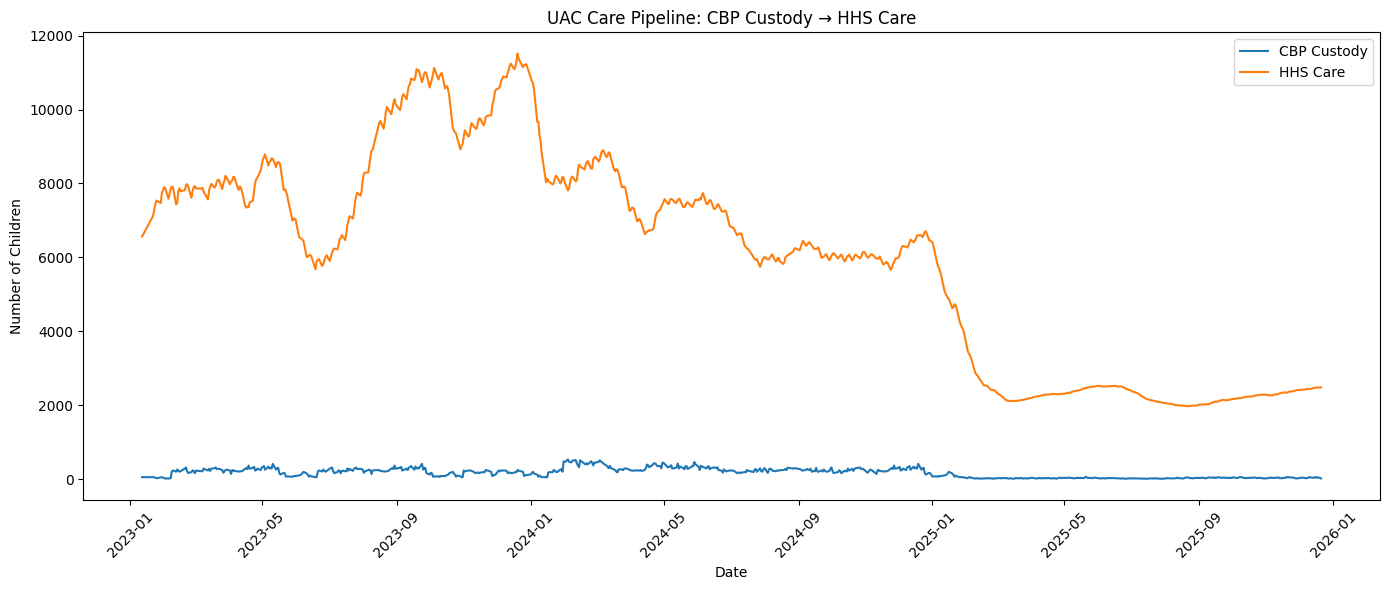

In [ ]:
# Visualization
plt.figure(figsize=(14, 6))

plt.plot(
    pipeline_df["date"],
    pipeline_df["cbp_custody"],
    label="CBP Custody"
)

plt.plot(
    pipeline_df["date"],
    pipeline_df["hhs_care"],
    label="HHS Care"
)

plt.title("UAC Care Pipeline: CBP Custody → HHS Care")
plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

• Define stages: CBP custody → HHS care → Sponsor placement

In [ ]:
# Define the UAC care pipeline stages

pipeline_stages = {
    "Stage 1": "CBP Custody",
    "Stage 2": "HHS Care",
    "Stage 3": "Sponsor Placement"
}

print("Care Pipeline:")
for stage, name in pipeline_stages.items():
    print(f"{stage}: {name}")

Care Pipeline:
Stage 1: CBP Custody
Stage 2: HHS Care
Stage 3: Sponsor Placement


In [ ]:
# map each stage to the dataset column
pipeline_columns = {
    "CBP Custody": "cbp_custody",
    "HHS Care": "hhs_care",
    "Sponsor Placement": "discharged"
}

print("\nPipeline Stage → Dataset Column")

for stage, column in pipeline_columns.items():
    print(f"{stage} → {column}")


Pipeline Stage → Dataset Column
CBP Custody → cbp_custody
HHS Care → hhs_care
Sponsor Placement → discharged


In [ ]:
# Create a pipeline DataFrame
pipeline_df = df[
    [
        "date",
        "cbp_custody",
        "transferred",
        "hhs_care",
        "discharged"
    ]
].copy()

pipeline_df.head()

,date,cbp_custody,transferred,hhs_care,discharged
0,2023-01-12,53.00,34.00,6566,436.00
1,2023-01-22,49.00,39.00,7122,227.00
2,2023-01-23,50.00,39.00,7280,181.00
3,2023-01-24,42.00,47.00,7433,175.00
4,2023-01-25,22.00,41.00,7538,180.00


In [ ]:
# Define the movement between stages
# movement from cbp custody to hhs care
pipeline_df["CBP_to_HHS"] = pipeline_df["transferred"]
# Movement from HHS Care to Sponsor placement
pipeline_df["HHS_to_Sponsor"] = pipeline_df["discharged"]

pipeline_df[
    [
        "date",
        "cbp_custody",
        "CBP_to_HHS",
        "hhs_care",
        "HHS_to_Sponsor",
        "discharged"
    ]
].head()

,date,cbp_custody,CBP_to_HHS,hhs_care,HHS_to_Sponsor,discharged
0,2023-01-12,53.00,34.00,6566,436.00,436.00
1,2023-01-22,49.00,39.00,7122,227.00,227.00
2,2023-01-23,50.00,39.00,7280,181.00,181.00
3,2023-01-24,42.00,47.00,7433,175.00,175.00
4,2023-01-25,22.00,41.00,7538,180.00,180.00


In [ ]:
# Display the pipeline structure
print("""
                UAC CARE PIPELINE

        ┌─────────────────────┐
        │     CBP CUSTODY     │
        │       Stage 1       │
        └──────────┬──────────┘
                   │
                   │ Transferred
                   ▼
        ┌─────────────────────┐
        │      HHS CARE        │
        │       Stage 2       │
        └──────────┬──────────┘
                   │
                   │ Discharged
                   ▼
        ┌─────────────────────┐
        │  SPONSOR PLACEMENT  │
        │       Stage 3       │
        └─────────────────────┘
""")


                UAC CARE PIPELINE

        ┌─────────────────────┐
        │     CBP CUSTODY     │
        │       Stage 1       │
        └──────────┬──────────┘
                   │
                   │ Transferred
                   ▼
        ┌─────────────────────┐
        │      HHS CARE        │
        │       Stage 2       │
        └──────────┬──────────┘
                   │
                   │ Discharged
                   ▼
        ┌─────────────────────┐
        │  SPONSOR PLACEMENT  │
        │       Stage 3       │
        └─────────────────────┘



Transition Efficiency Metrics

Transfer Efficiency Ratio=
Transfers / CBP Custody
	​


In [ ]:
# Transfer Efficiency Ratio
df["Transfer_Efficiency_Ratio"] = (
    df["transferred"] / df["cbp_custody"]
)

df["Transfer_Efficiency_%"] = (
    df["Transfer_Efficiency_Ratio"] * 100
)

df[[
    "date",
    "cbp_custody",
    "transferred",
    "Transfer_Efficiency_Ratio",
    "Transfer_Efficiency_%"
]].head()

,date,cbp_custody,transferred,Transfer_Efficiency_Ratio,Transfer_Efficiency_%
0,2023-01-12,53.00,34.00,0.64,64.15
1,2023-01-22,49.00,39.00,0.80,79.59
2,2023-01-23,50.00,39.00,0.78,78.00
3,2023-01-24,42.00,47.00,1.12,111.90
4,2023-01-25,22.00,41.00,1.86,186.36


In [ ]:
df = pipeline_df.copy()
# discharge effectiveness
# Discharge Effectiveness = Discharge/ HHS Care
df["Discharge_Effectiveness"] = (
    df["discharged"] / df["hhs_care"]
)

df["Discharge_Effectiveness_%"] = (
    df["Discharge_Effectiveness"] * 100
)

df[[
    "date",
    "hhs_care",
    "discharged",
    "Discharge_Effectiveness",
    "Discharge_Effectiveness_%"
]].head()

,date,hhs_care,discharged,Discharge_Effectiveness,Discharge_Effectiveness_%
0,2023-01-12,6566,436.00,0.07,6.64
1,2023-01-22,7122,227.00,0.03,3.19
2,2023-01-23,7280,181.00,0.02,2.49
3,2023-01-24,7433,175.00,0.02,2.35
4,2023-01-25,7538,180.00,0.02,2.39


In [ ]:
import pandas as pd


# Remove completely empty rows
df = df.dropna(how="all").copy()

# Clean column names
df.columns = df.columns.str.strip()

# Rename columns
df = df.rename(columns={
    "Date": "date",
    "Children apprehended and placed in CBP custody*": "apprehended",
    "Children in CBP custody": "cbp_custody",
    "Children transferred out of CBP custody": "transferred",
    "Children in HHS Care": "hhs_care",
    "Children discharged from HHS Care": "discharged"
})

print(df.columns.tolist())

['date', 'cbp_custody', 'transferred', 'hhs_care', 'discharged', 'CBP_to_HHS', 'HHS_to_Sponsor', 'Discharge_Effectiveness', 'Discharge_Effectiveness_%']


In [ ]:
import pandas as pd


# Re-read the original data to get the 'apprehended' column
temp_df_for_apprehended = pd.read_csv(file_path)
temp_df_for_apprehended = temp_df_for_apprehended.dropna(how="all").copy()

# Clean and rename the 'apprehended' related column
original_apprehended_col_name = "Children apprehended and placed in CBP custody*"
temp_df_for_apprehended["Date"] = pd.to_datetime(temp_df_for_apprehended["Date"], errors="coerce")
temp_df_for_apprehended[original_apprehended_col_name] = (
    temp_df_for_apprehended[original_apprehended_col_name]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.strip()
)
temp_df_for_apprehended[original_apprehended_col_name] = pd.to_numeric(temp_df_for_apprehended[original_apprehended_col_name], errors="coerce")

# Rename the column to 'apprehended' and 'Date' to 'date' for merging
temp_df_for_apprehended = temp_df_for_apprehended.rename(columns={
    "Date": "date",
    original_apprehended_col_name: "apprehended"
})

# Merge the 'apprehended' column from temp_df_for_apprehended into the current 'df'
# using 'date' as the key.
# We only need the 'date' and 'apprehended' columns from the temporary DataFrame for merging.
df = pd.merge(df, temp_df_for_apprehended[['date', 'apprehended']], on='date', how='left')

# Pipeline Throughput Rate
# Pipeline Throughput Rate = {Total Exits}/{Total Entries}
# Total entries into the pipeline
total_entries = df["apprehended"].sum()

# Total exits from the pipeline
total_exits = df["discharged"].sum()

# Pipeline Throughput Rate
pipeline_throughput_rate = total_exits / total_entries

# Percentage
pipeline_throughput_pct = pipeline_throughput_rate * 100

print("Total Entries:", total_entries)
print("Total Exits:", total_exits)
print("Pipeline Throughput Rate:", pipeline_throughput_rate)
print("Pipeline Throughput (%):", pipeline_throughput_pct)

Total Entries: 67337.0
Total Exits: 124853.0
Pipeline Throughput Rate: 1.8541515066011256
Pipeline Throughput (%): 185.41515066011257


In [ ]:
# create a summary table
# Transition Efficiency Metrics Summary

transition_metrics = pd.DataFrame({
    "Metric": [
        "Transfer Efficiency Ratio",
        "Discharge Effectiveness",
        "Pipeline Throughput Rate"
    ],

    "Formula": [
        "Transfers ÷ CBP Custody",
        "Discharges ÷ HHS Care",
        "Total Exits ÷ Total Entries"
    ],

    "Value": [
        df["transferred"].sum() / df["cbp_custody"].sum(),
        df["discharged"].sum() / df["hhs_care"].sum(),
        df["discharged"].sum() / df["apprehended"].sum()
    ]
})

transition_metrics["Percentage"] = (
    transition_metrics["Value"] * 100
)

transition_metrics

,Metric,Formula,Value,Percentage
0,Transfer Efficiency Ratio,Transfers ÷ CBP Custody,0.75,75.03
1,Discharge Effectiveness,Discharges ÷ HHS Care,0.03,2.86
2,Pipeline Throughput Rate,Total Exits ÷ Total Entries,1.85,185.42


Backlog & Delay Identification

In [ ]:
# Compare Inflow vs Successful Exits
# Inflow=Transfers into HHS
# Successful Exits = Discharges from HHS
# -----------------------------------------
# 1. INFLOW VS SUCCESSFUL EXITS
# -----------------------------------------

df["inflow"] = df["transferred"]

df["successful_exits"] = df["discharged"]

# Difference between inflow and exits
df["net_flow"] = (
    df["inflow"] - df["successful_exits"]
)

df[
    [
        "date",
        "inflow",
        "successful_exits",
        "net_flow"
    ]
].head(10)

,date,inflow,successful_exits,net_flow
0,2023-01-12,34.00,436.00,-402.00
1,2023-01-22,39.00,227.00,-188.00
2,2023-01-23,39.00,181.00,-142.00
3,2023-01-24,47.00,175.00,-128.00
4,2023-01-25,41.00,180.00,-139.00
5,2023-01-29,11.00,303.00,-292.00
6,2023-01-30,29.00,196.00,-167.00
7,2023-01-31,36.00,158.00,-122.00
8,2023-02-01,27.00,231.00,-204.00
9,2023-02-02,23.00,298.00,-275.00


In [ ]:
# Interpret net_flow
def classify_flow(net_flow):
    if net_flow > 0:
        return "Inflow > Exits"
    elif net_flow < 0:
        return "Exits > Inflow"
    else:
        return "Balanced"

df["flow_status"] = df["net_flow"].apply(classify_flow)

df[
    [
        "date",
        "inflow",
        "successful_exits",
        "net_flow",
        "flow_status"
    ]
].head(10)

,date,inflow,successful_exits,net_flow,flow_status
0,2023-01-12,34.00,436.00,-402.00,Exits > Inflow
1,2023-01-22,39.00,227.00,-188.00,Exits > Inflow
2,2023-01-23,39.00,181.00,-142.00,Exits > Inflow
3,2023-01-24,47.00,175.00,-128.00,Exits > Inflow
4,2023-01-25,41.00,180.00,-139.00,Exits > Inflow
5,2023-01-29,11.00,303.00,-292.00,Exits > Inflow
6,2023-01-30,29.00,196.00,-167.00,Exits > Inflow
7,2023-01-31,36.00,158.00,-122.00,Exits > Inflow
8,2023-02-01,27.00,231.00,-204.00,Exits > Inflow
9,2023-02-02,23.00,298.00,-275.00,Exits > Inflow


Exits > Inflow → more children exited than entered → potential backlog reduction

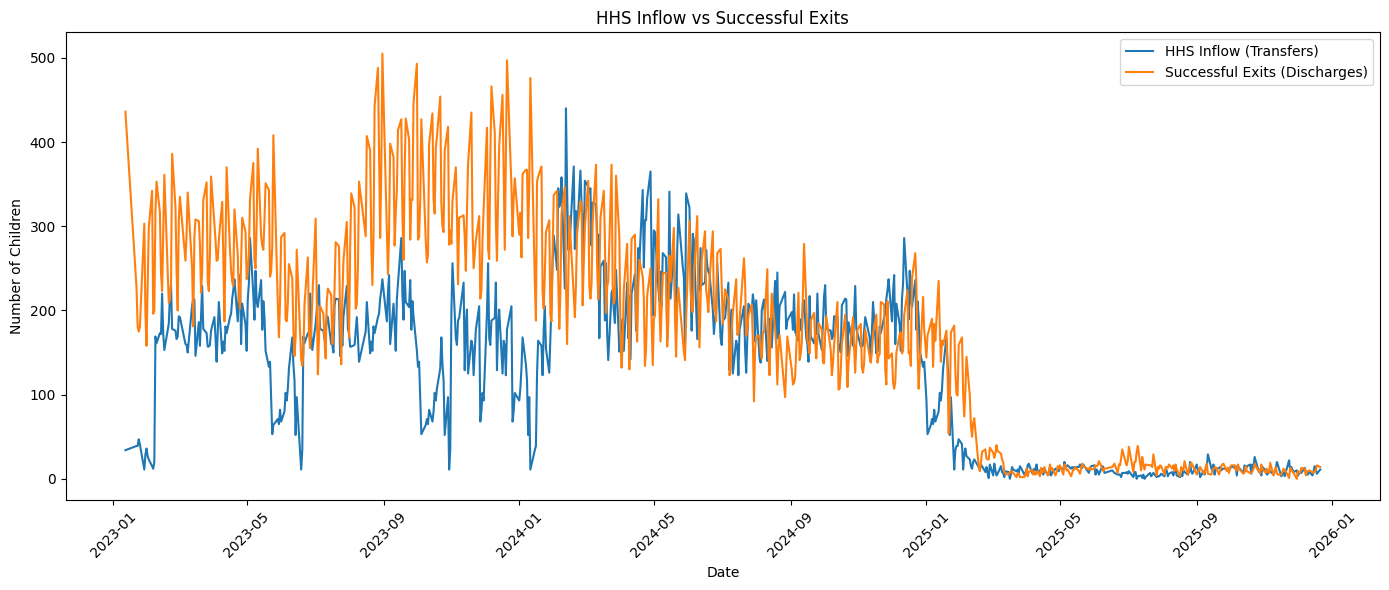

In [ ]:
# Visualize Inflow vs Successful Exits
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))
plt.plot(
    df["date"],
    df["inflow"],
    label = "HHS Inflow (Transfers)"
)

plt.plot(
    df["date"],
    df["successful_exits"],
    label="Successful Exits (Discharges)"
)

plt.title("HHS Inflow vs Successful Exits")
plt.xlabel("Date")
plt.ylabel("Number of Children")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

The comparison of HHS inflows and successful exits shows substantial variability during 2023 and early 2024, with periods where transfers exceeded discharges and periods where discharges exceeded transfers. From mid-2024 onward, inflows and successful exits became more closely aligned. A pronounced reduction in both measures is observed in early 2025, followed by relatively low-volume activity.

In [ ]:
# Identify Sustained Imbalance Periods
# -----------------------------------------
# 2. IDENTIFY SUSTAINED IMBALANCE
# -----------------------------------------

df["imbalance"] = df["inflow"] > df["successful_exits"]

# Create groups whenever the imbalance status changes
df["imbalance_group"] = (
    df["imbalance"] != df["imbalance"].shift()
).cumsum()

In [ ]:
imbalance_periods = (
    df.groupby("imbalance_group")
      .agg(
          start_date=("date", "min"),
          end_date=("date", "max"),
          observations=("date", "count"),
          sustained_imbalance=("imbalance", "first"),
          total_inflow=("inflow", "sum"),
          total_exits=("successful_exits", "sum")
      )
      .reset_index()
)

imbalance_periods

,imbalance_group,start_date,end_date,observations,sustained_imbalance,total_inflow,total_exits
0,1,2023-01-12,2023-02-20,21,False,"1,777.00","5,437.00"
1,2,2023-02-21,2023-02-21,1,True,217.00,213.00
2,3,2023-02-22,2023-03-13,11,False,"1,979.00","3,170.00"
3,4,2023-03-14,2023-03-14,1,True,214.00,181.00
4,5,2023-03-15,2023-04-23,28,False,"5,077.00","7,807.00"
...,...,...,...,...,...,...,...
170,171,2025-12-04,2025-12-04,1,False,7.00,13.00
171,172,2025-12-07,2025-12-08,2,True,22.00,16.00
172,173,2025-12-09,2025-12-14,4,False,25.00,35.00
173,174,2025-12-15,2025-12-17,3,True,35.00,26.00


In [ ]:
sustained_imbalance = imbalance_periods[
    (imbalance_periods["sustained_imbalance"] == True) &
    (imbalance_periods["observations"] >= 3)
].copy()

sustained_imbalance

,imbalance_group,start_date,end_date,observations,sustained_imbalance,total_inflow,total_exits
21,22,2024-02-05,2024-02-08,4,True,"1,356.00",957.00
23,24,2024-02-12,2024-02-14,3,True,"1,061.00",624.00
25,26,2024-02-19,2024-02-21,3,True,962.00,641.00
29,30,2024-02-27,2024-02-29,3,True,934.00,762.00
31,32,2024-03-04,2024-03-07,4,True,"1,290.00",980.00
43,44,2024-04-21,2024-05-02,10,True,"2,943.00","1,915.00"
45,46,2024-05-06,2024-05-15,8,True,"1,919.00","1,667.00"
47,48,2024-05-20,2024-06-03,10,True,"2,546.00","1,951.00"
51,52,2024-06-10,2024-06-12,3,True,727.00,580.00
53,54,2024-06-17,2024-06-20,4,True,"1,014.00",871.00


In [ ]:
# Calculate the Imbalance Magnitude
sustained_imbalance["net_accumulation"] = (
    sustained_imbalance["total_inflow"]
    - sustained_imbalance["total_exits"]
)

sustained_imbalance[
    [
        "start_date",
        "end_date",
        "observations",
        "total_inflow",
        "total_exits",
        "net_accumulation"
    ]
]

,start_date,end_date,observations,total_inflow,total_exits,net_accumulation
21,2024-02-05,2024-02-08,4,"1,356.00",957.00,399.00
23,2024-02-12,2024-02-14,3,"1,061.00",624.00,437.00
25,2024-02-19,2024-02-21,3,962.00,641.00,321.00
29,2024-02-27,2024-02-29,3,934.00,762.00,172.00
31,2024-03-04,2024-03-07,4,"1,290.00",980.00,310.00
43,2024-04-21,2024-05-02,10,"2,943.00","1,915.00","1,028.00"
45,2024-05-06,2024-05-15,8,"1,919.00","1,667.00",252.00
47,2024-05-20,2024-06-03,10,"2,546.00","1,951.00",595.00
51,2024-06-10,2024-06-12,3,727.00,580.00,147.00
53,2024-06-17,2024-06-20,4,"1,014.00",871.00,143.00


In [ ]:
# Detect Accumulation of Unresolved Cases
# Net Accumulation=Inflow−Successful Exits
# Cumulative Accumulation=∑(Inflow−Successful Exits)
# -----------------------------------------
# 3. CUMULATIVE ACCUMULATION
# -----------------------------------------

df["cumulative_accumulation"] = (
    df["net_flow"].cumsum()
)

df[
    [
        "date",
        "inflow",
        "successful_exits",
        "net_flow",
        "cumulative_accumulation"
    ]
].head(10)

,date,inflow,successful_exits,net_flow,cumulative_accumulation
0,2023-01-12,34.00,436.00,-402.00,-402.00
1,2023-01-22,39.00,227.00,-188.00,-590.00
2,2023-01-23,39.00,181.00,-142.00,-732.00
3,2023-01-24,47.00,175.00,-128.00,-860.00
4,2023-01-25,41.00,180.00,-139.00,-999.00
5,2023-01-29,11.00,303.00,-292.00,"-1,291.00"
6,2023-01-30,29.00,196.00,-167.00,"-1,458.00"
7,2023-01-31,36.00,158.00,-122.00,"-1,580.00"
8,2023-02-01,27.00,231.00,-204.00,"-1,784.00"
9,2023-02-02,23.00,298.00,-275.00,"-2,059.00"


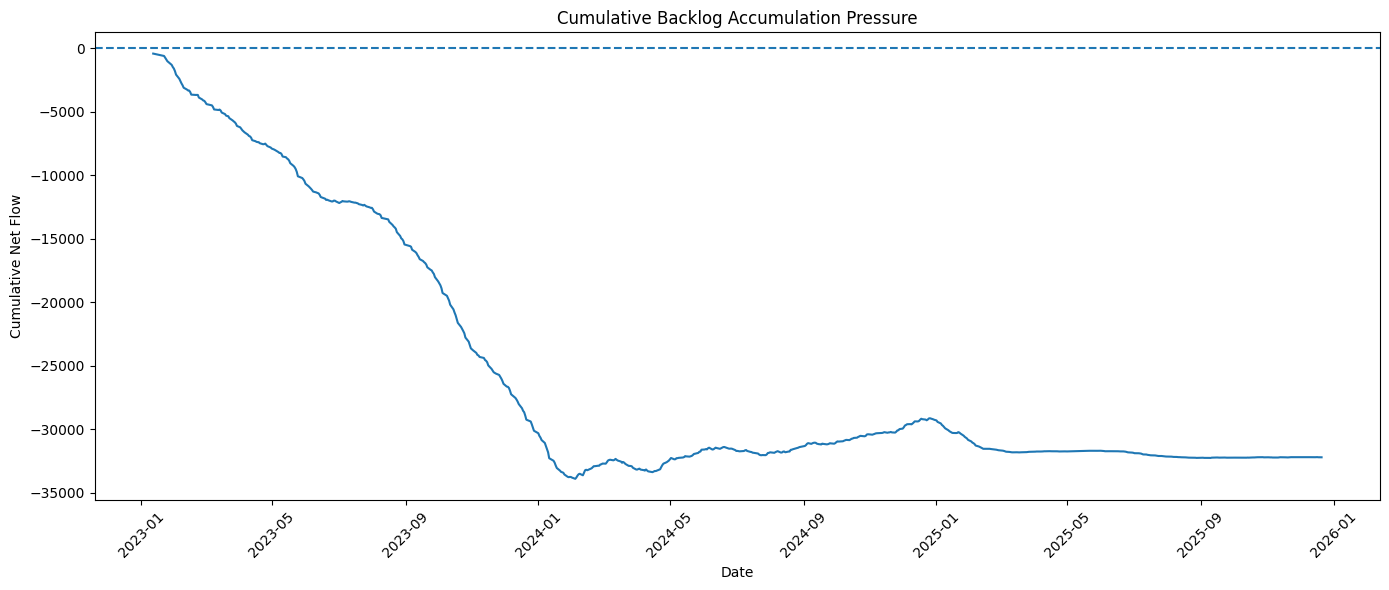

In [ ]:
# Plot Cumulative Accumulation
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["cumulative_accumulation"]
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Cumulative Backlog Accumulation Pressure")
plt.xlabel("Date")
plt.ylabel("Cumulative Net Flow")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# Detect High Accumulation Periods
positive_net_flow = df.loc[
    df["net_flow"] > 0,
    "net_flow"
]

threshold = positive_net_flow.quantile(0.75)

print("High Accumulation Threshold:", threshold)

High Accumulation Threshold: 57.75


In [ ]:
df["accumulation_alert"] = (
    df["net_flow"] >= threshold
)

df[
    [
        "date",
        "inflow",
        "successful_exits",
        "net_flow",
        "accumulation_alert"
    ]
].head(20)

,date,inflow,successful_exits,net_flow,accumulation_alert
0,2023-01-12,34.00,436.00,-402.00,False
1,2023-01-22,39.00,227.00,-188.00,False
2,2023-01-23,39.00,181.00,-142.00,False
3,2023-01-24,47.00,175.00,-128.00,False
4,2023-01-25,41.00,180.00,-139.00,False
5,2023-01-29,11.00,303.00,-292.00,False
6,2023-01-30,29.00,196.00,-167.00,False
7,2023-01-31,36.00,158.00,-122.00,False
8,2023-02-01,27.00,231.00,-204.00,False
9,2023-02-02,23.00,298.00,-275.00,False


In [ ]:
# Identify the Highest Backlog-Pressure Periods
high_pressure_periods = df[
    df["accumulation_alert"] == True
].sort_values(
    by="net_flow",
    ascending=False
)

high_pressure_periods[
    [
        "date",
        "inflow",
        "successful_exits",
        "net_flow",
        "hhs_care"
    ]
].head(10)

,date,inflow,successful_exits,net_flow,hhs_care
259,2024-02-12,440.00,234.00,206.00,8092
260,2024-02-13,349.00,160.00,189.00,8348
309,2024-04-23,307.00,134.00,173.00,6967
263,2024-02-19,371.00,218.00,153.00,8380
310,2024-04-24,307.00,154.00,153.00,7128
335,2024-05-30,339.00,190.00,149.00,7563
255,2024-02-06,323.00,178.00,145.00,8045
461,2024-12-03,242.00,107.00,135.00,6192
391,2024-08-20,245.00,112.00,133.00,5995
274,2024-03-05,345.00,214.00,131.00,8800


Temporal and Pattern Analysis

In [ ]:
# step-1 Create Weekday/ weekend variable
# Make sure date is datetime
df["date"] = pd.to_datetime(df["date"])

# Extract day information
df["day_of_week"] = df["date"].dt.day_name()

# Classify weekday vs weekend
df["day_type"] = df["date"].dt.dayofweek.apply(
    lambda x: "Weekend" if x >= 5 else "Weekday"
)

df[
    ["date", "day_of_week", "day_type"]
].head(10)

,date,day_of_week,day_type
0,2023-01-12,Thursday,Weekday
1,2023-01-22,Sunday,Weekend
2,2023-01-23,Monday,Weekday
3,2023-01-24,Tuesday,Weekday
4,2023-01-25,Wednesday,Weekday
5,2023-01-29,Sunday,Weekend
6,2023-01-30,Monday,Weekday
7,2023-01-31,Tuesday,Weekday
8,2023-02-01,Wednesday,Weekday
9,2023-02-02,Thursday,Weekday


In [ ]:
# Calculate transition efficiency
# Transfer Efficiency
df["transfer_efficiency"] = (
    df["transferred"] / df["cbp_custody"]
)

# Discharge Effectiveness
df["discharge_effectiveness"] = (
    df["discharged"] / df["hhs_care"]
)

# Convert to percentages
df["transfer_efficiency_pct"] = (
    df["transfer_efficiency"] * 100
)

df["discharge_effectiveness_pct"] = (
    df["discharge_effectiveness"] * 100
)

In [ ]:
# compare weekdays vs weekend
weekday_weekend = (
    df.groupby("day_type")
      .agg(
          observations=("date", "count"),
          avg_transfer_efficiency=(
              "transfer_efficiency_pct", "mean"
          ),
          avg_discharge_effectiveness=(
              "discharge_effectiveness_pct", "mean"
          ),
          avg_transfers=("transferred", "mean"),
          avg_discharges=("discharged", "mean")
      )
      .reset_index()
)

weekday_weekend

,day_type,observations,avg_transfer_efficiency,avg_discharge_effectiveness,avg_transfers,avg_discharges
0,Weekday,590,68.90,2.27,128.36,166.19
1,Weekend,130,70.01,2.84,130.06,206.14


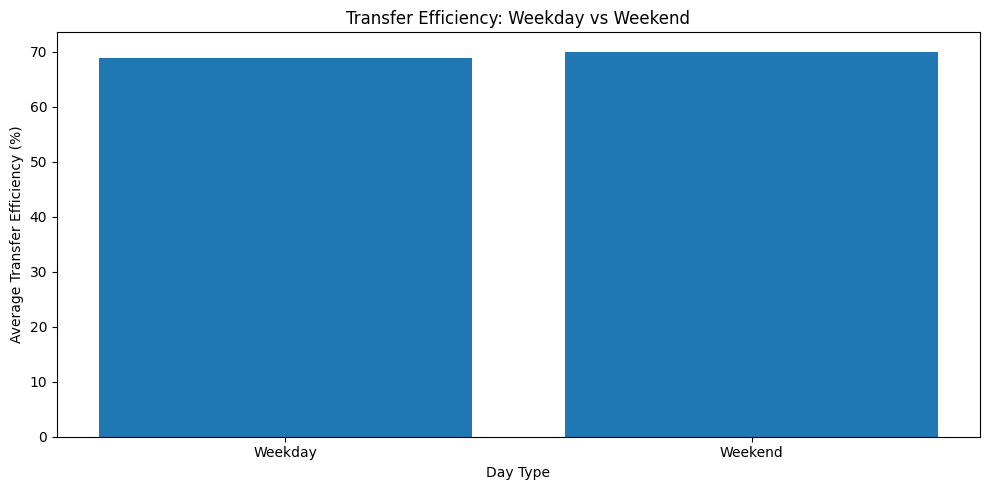

In [ ]:
# visualization
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    weekday_weekend["day_type"],
    weekday_weekend["avg_transfer_efficiency"]
)

plt.title("Transfer Efficiency: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Transfer Efficiency (%)")

plt.tight_layout()
plt.show()

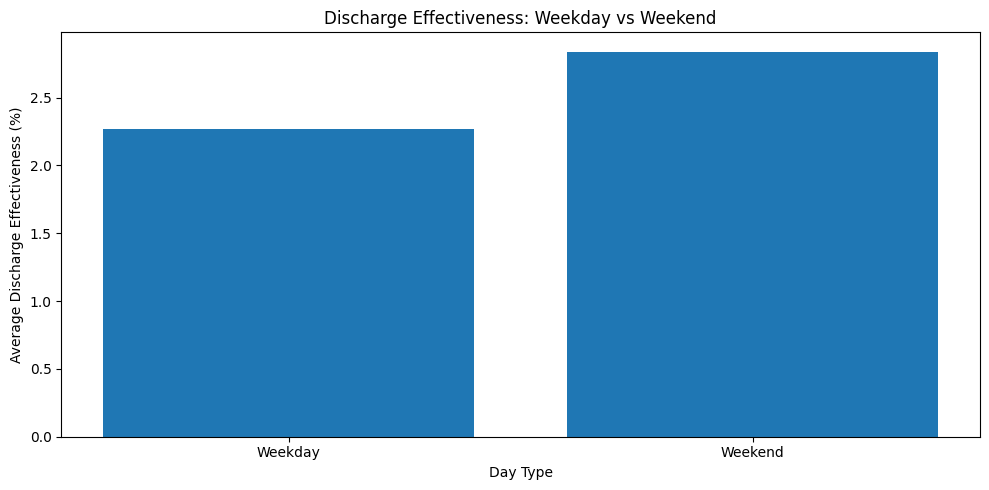

In [ ]:
# discharge effectiveness
plt.figure(figsize=(10, 5))

plt.bar(
    weekday_weekend["day_type"],
    weekday_weekend["avg_discharge_effectiveness"]
)

plt.title("Discharge Effectiveness: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Discharge Effectiveness (%)")

plt.tight_layout()
plt.show()

In [ ]:
day_of_week_analysis = (
    df.groupby("day_of_week")
      .agg(
          observations=("date", "count"),
          avg_transfers=("transferred", "mean"),
          avg_discharges=("discharged", "mean"),
          avg_transfer_efficiency=(
              "transfer_efficiency_pct", "mean"
          ),
          avg_discharge_effectiveness=(
              "discharge_effectiveness_pct", "mean"
          )
      )
      .reset_index()
)

day_of_week_analysis

,day_of_week,observations,avg_transfers,avg_discharges,avg_transfer_efficiency,avg_discharge_effectiveness
0,Friday,2,110.00,144.00,71.18,2.40
1,Monday,145,123.73,157.56,66.05,2.17
2,Sunday,130,130.06,206.14,70.01,2.84
3,Thursday,147,133.41,205.69,73.26,2.79
4,Tuesday,149,124.86,136.11,67.05,1.87
5,Wednesday,147,131.67,166.01,69.20,2.26


In [ ]:
# Month-over-Month Placement Trends
# step - 1 create month variable
df["month"] = df["date"].dt.to_period("M")

# step - 2 calculate monthly placement volume
monthly_placement = (
    df.groupby("month")
      .agg(
          total_discharges=("discharged", "sum"),
          avg_discharges=("discharged", "mean"),
          total_transfers=("transferred", "sum"),
          avg_hhs_care=("hhs_care", "mean")
      )
      .reset_index()
)

monthly_placement

# step - 3 Calculate month over month change
monthly_placement["MoM_change"] = (
    monthly_placement["total_discharges"].diff()
)

monthly_placement["MoM_change_pct"] = (
    monthly_placement["total_discharges"]
    .pct_change()
    * 100
)

monthly_placement


,month,total_discharges,avg_discharges,total_transfers,avg_hhs_care,MoM_change,MoM_change_pct
0,2023-01,"1,856.00",232.00,276.00,"7,369.62",NaN,NaN
1,2023-02,"5,183.00",272.79,"2,637.00","7,795.79","3,327.00",179.26
2,2023-03,"5,375.00",282.89,"3,399.00","7,945.37",192.00,3.70
3,2023-04,"5,668.00",269.90,"3,967.00","7,842.67",293.00,5.45
4,2023-05,"6,256.00",284.36,"3,622.00","8,187.14",588.00,10.37
5,2023-06,"4,029.00",201.45,"2,416.00","6,136.45","-2,227.00",-35.60
6,2023-07,"4,407.00",209.86,"3,897.00","6,828.10",378.00,9.38
7,2023-08,"6,470.00",323.50,"3,587.00","9,347.90","2,063.00",46.81
8,2023-09,"6,546.00",344.53,"3,971.00","10,701.32",76.00,1.17
9,2023-10,"7,658.00",348.09,"2,049.00","10,205.32","1,112.00",16.99


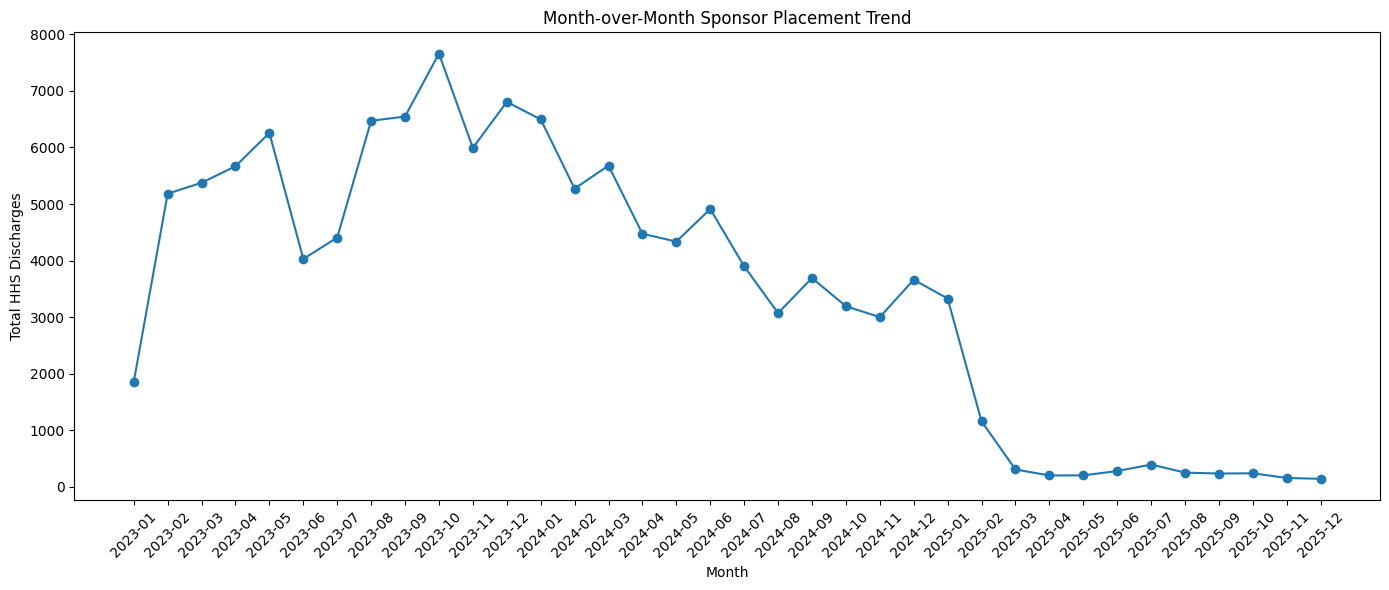

In [ ]:
# step 4 plot monthly placement trend
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_placement["month"].astype(str),
    monthly_placement["total_discharges"],
    marker="o"
)

plt.title("Month-over-Month Sponsor Placement Trend")
plt.xlabel("Month")
plt.ylabel("Total HHS Discharges")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

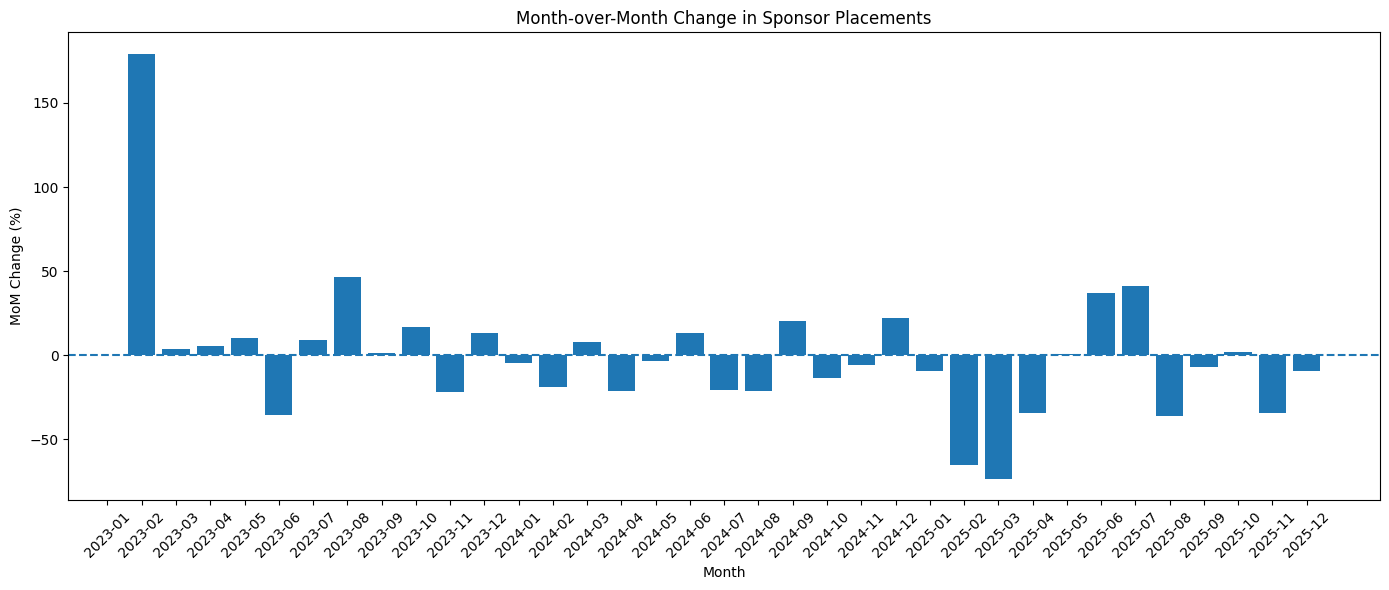

In [ ]:
# step - 5 plot MoM percentage change
plt.figure(figsize=(14, 6))

plt.bar(
    monthly_placement["month"].astype(str),
    monthly_placement["MoM_change_pct"]
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Month-over-Month Change in Sponsor Placements")
plt.xlabel("Month")
plt.ylabel("MoM Change (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Identify prolonged stagnation periods
# step -1 Calculate stagnation threshold
stagnation_threshold = df["discharged"].quantile(0.25)

print(
    "Stagnation Threshold:",
    stagnation_threshold
)

Stagnation Threshold: 19.75


In [ ]:
# step-2 Flag low discharge observations
df["stagnation_flag"] = (
    df["discharged"] <= stagnation_threshold
)

df[
    [
        "date",
        "discharged",
        "stagnation_flag"
    ]
].head(20)

,date,discharged,stagnation_flag
0,2023-01-12,436.00,False
1,2023-01-22,227.00,False
2,2023-01-23,181.00,False
3,2023-01-24,175.00,False
4,2023-01-25,180.00,False
5,2023-01-29,303.00,False
6,2023-01-30,196.00,False
7,2023-01-31,158.00,False
8,2023-02-01,231.00,False
9,2023-02-02,298.00,False


In [ ]:
# Find Consecutive Stagnation Periods
# Create a group whenever stagnation status changes

df["stagnation_group"] = (
    df["stagnation_flag"]
    != df["stagnation_flag"].shift()
).cumsum()

In [ ]:
stagnation_periods = (
    df.groupby("stagnation_group")
      .agg(
          start_date=("date", "min"),
          end_date=("date", "max"),
          observations=("date", "count"),
          stagnation=("stagnation_flag", "first"),
          total_discharges=("discharged", "sum"),
          avg_discharges=("discharged", "mean")
      )
      .reset_index()
)

stagnation_periods

,stagnation_group,start_date,end_date,observations,stagnation,total_discharges,avg_discharges
0,1,2023-01-12,2025-02-13,513,False,"122,206.00",238.22
1,2,2025-02-17,2025-02-19,3,True,43.00,14.33
2,3,2025-02-20,2025-03-11,14,False,406.00,29.00
3,4,2025-03-12,2025-06-04,59,True,544.00,9.22
4,5,2025-06-05,2025-06-05,1,False,21.00,21.00
5,6,2025-06-08,2025-06-24,8,True,106.00,13.25
6,7,2025-06-25,2025-06-29,3,False,79.00,26.33
7,8,2025-06-30,2025-06-30,1,True,16.00,16.00
8,9,2025-07-01,2025-07-02,2,False,60.00,30.00
9,10,2025-07-06,2025-07-06,1,True,8.00,8.00


In [ ]:
# Identify Prolonged Stagnation
prolonged_stagnation = stagnation_periods[
    (stagnation_periods["stagnation"] == True) &
    (stagnation_periods["observations"] >= 3)
].copy()

prolonged_stagnation

,stagnation_group,start_date,end_date,observations,stagnation,total_discharges,avg_discharges
1,2,2025-02-17,2025-02-19,3,True,43.00,14.33
3,4,2025-03-12,2025-06-04,59,True,544.00,9.22
5,6,2025-06-08,2025-06-24,8,True,106.00,13.25
13,14,2025-07-15,2025-07-23,6,True,91.00,15.17
15,16,2025-07-27,2025-08-20,19,True,227.00,11.95
17,18,2025-08-24,2025-12-21,82,True,849.00,10.35


In [ ]:
prolonged_stagnation[
    [
        "start_date",
        "end_date",
        "observations",
        "total_discharges",
        "avg_discharges"
    ]
]

,start_date,end_date,observations,total_discharges,avg_discharges
1,2025-02-17,2025-02-19,3,43.00,14.33
3,2025-03-12,2025-06-04,59,544.00,9.22
5,2025-06-08,2025-06-24,8,106.00,13.25
13,2025-07-15,2025-07-23,6,91.00,15.17
15,2025-07-27,2025-08-20,19,227.00,11.95
17,2025-08-24,2025-12-21,82,849.00,10.35


In [ ]:
# Calculate Duration of Stagnation
prolonged_stagnation["calendar_days"] = (
    prolonged_stagnation["end_date"]
    - prolonged_stagnation["start_date"]
).dt.days + 1

prolonged_stagnation[
    [
        "start_date",
        "end_date",
        "observations",
        "calendar_days",
        "avg_discharges"
    ]
]

,start_date,end_date,observations,calendar_days,avg_discharges
1,2025-02-17,2025-02-19,3,3,14.33
3,2025-03-12,2025-06-04,59,85,9.22
5,2025-06-08,2025-06-24,8,17,13.25
13,2025-07-15,2025-07-23,6,9,15.17
15,2025-07-27,2025-08-20,19,25,11.95
17,2025-08-24,2025-12-21,82,120,10.35


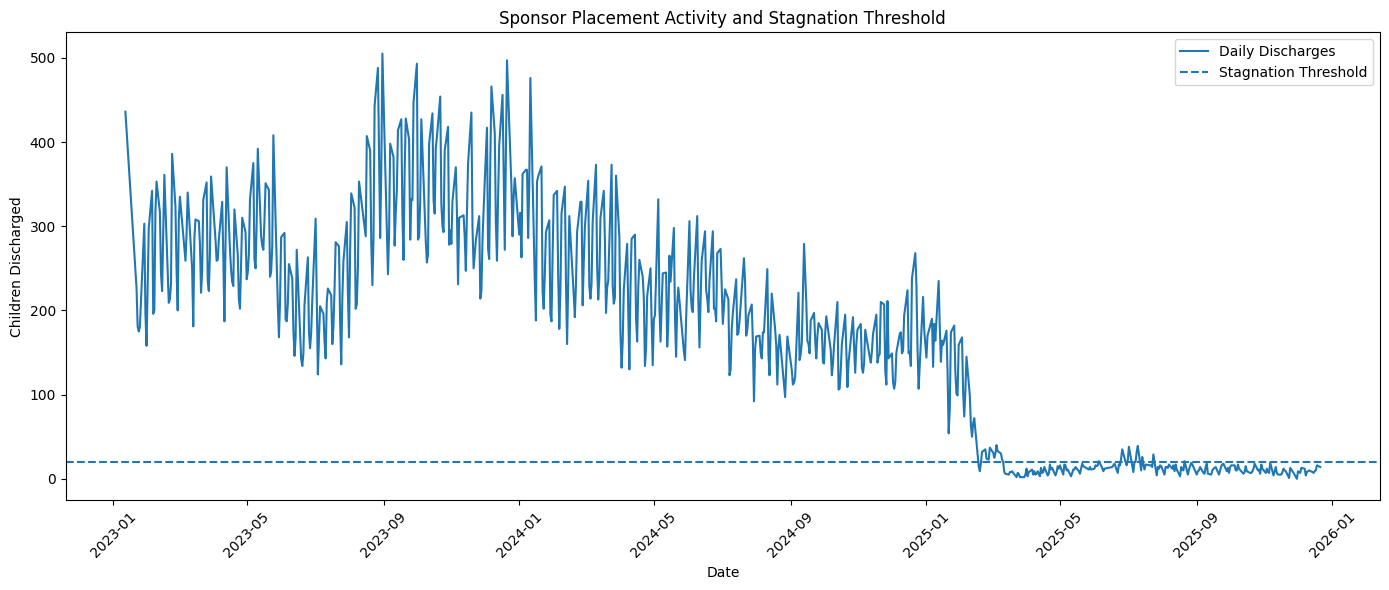

In [ ]:
# Visualization of stagnation
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["discharged"],
    label="Daily Discharges"
)

plt.axhline(
    y=stagnation_threshold,
    linestyle="--",
    label="Stagnation Threshold"
)

plt.title("Sponsor Placement Activity and Stagnation Threshold")
plt.xlabel("Date")
plt.ylabel("Children Discharged")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Outcome Stability Analysis

In [ ]:
# 1. Variability in Discharge Performance


discharge_stats = df["discharged"].describe()

print("Discharge Performance Statistics:")
print(discharge_stats)

Discharge Performance Statistics:
count   720.00
mean    173.41
std     125.70
min       0.00
25%      19.75
50%     181.00
75%     267.00
max     505.00
Name: discharged, dtype: float64


In [ ]:
# Calculate Coefficient of Variation
# Coefficient of Variation

discharge_mean = df["discharged"].mean()
discharge_std = df["discharged"].std()

discharge_cv = discharge_std / discharge_mean

print("Average Discharges:", discharge_mean)
print("Standard Deviation:", discharge_std)
print("Coefficient of Variation:", discharge_cv)
print("CV (%):", discharge_cv * 100)

Average Discharges: 173.40694444444443
Standard Deviation: 125.7028405572816
Coefficient of Variation: 0.7249008450036664
CV (%): 72.49008450036663


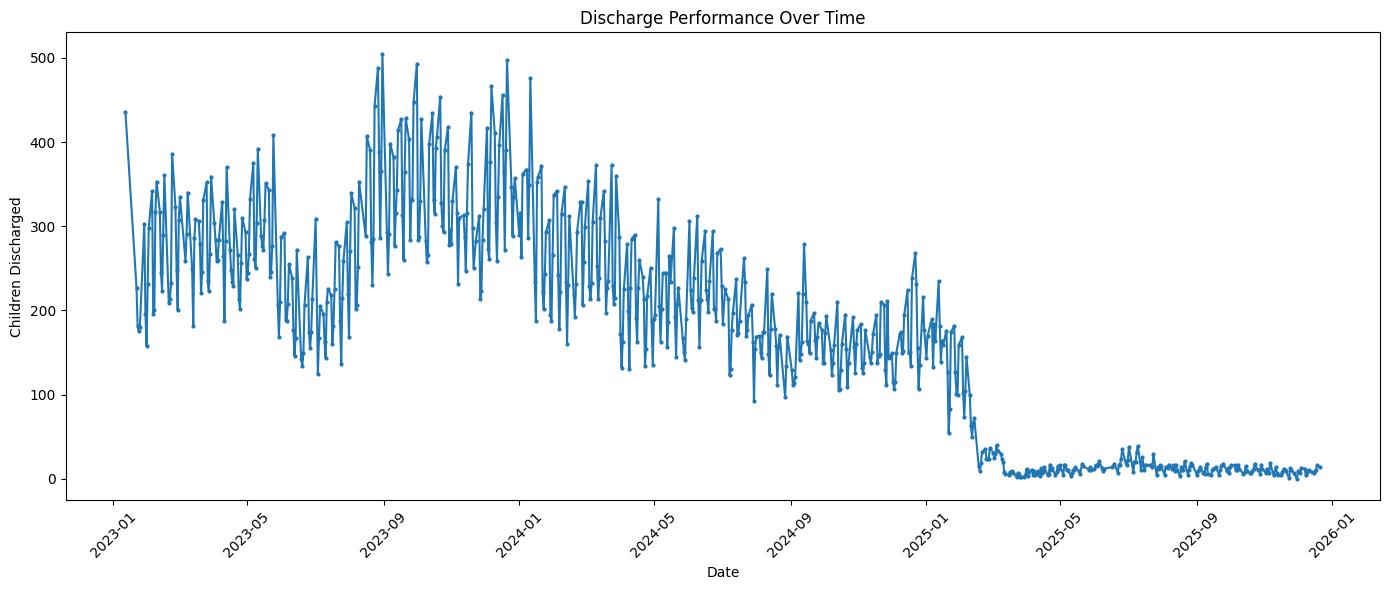

In [ ]:
# 2. Visualize Discharge Variability

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["discharged"],
    marker="o",
    markersize=2
)

plt.title("Discharge Performance Over Time")
plt.xlabel("Date")
plt.ylabel("Children Discharged")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# 3. Consistency of Placement Outcomes
df["discharge_rolling_mean"] = (
    df["discharged"]
    .rolling(window=7)
    .mean()
)

df["discharge_rolling_std"] = (
    df["discharged"]
    .rolling(window=7)
    .std()
)

In [ ]:
# Calculate rolling coefficient of variation
df["rolling_cv"] = (
    df["discharge_rolling_std"]
    / df["discharge_rolling_mean"]
)

In [ ]:
df[
    [
        "date",
        "discharged",
        "discharge_rolling_mean",
        "discharge_rolling_std",
        "rolling_cv"
    ]
].tail(20)

,date,discharged,discharge_rolling_mean,discharge_rolling_std,rolling_cv
700,2025-11-23,1.00,7.14,3.72,0.52
701,2025-11-24,13.00,8.29,4.15,0.50
702,2025-11-25,11.00,9.14,3.98,0.43
703,2025-11-27,7.00,9.00,4.04,0.45
704,2025-11-30,0.00,7.29,4.99,0.68
705,2025-12-01,9.00,7.14,4.91,0.69
706,2025-12-02,8.00,7.00,4.86,0.69
707,2025-12-03,7.00,7.86,4.10,0.52
708,2025-12-04,13.00,7.86,4.10,0.52
709,2025-12-07,12.00,8.00,4.24,0.53


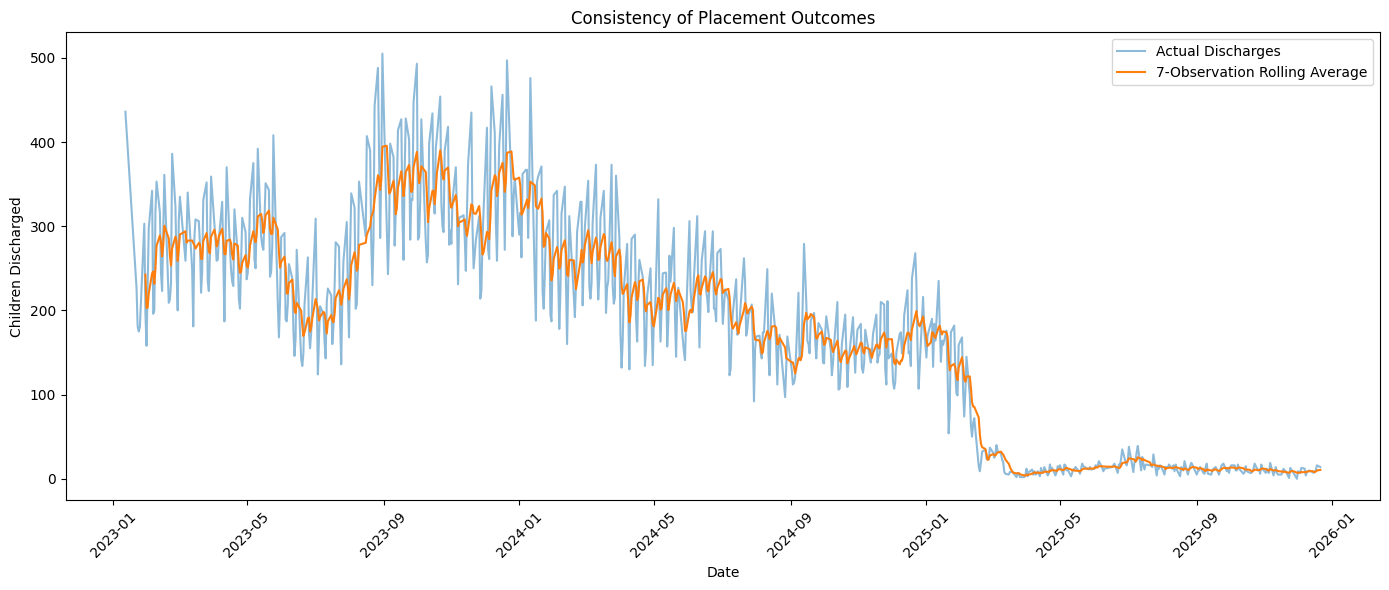

In [ ]:
# visualize the rolling average
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["discharged"],
    label="Actual Discharges",
    alpha=0.5
)

plt.plot(
    df["date"],
    df["discharge_rolling_mean"],
    label="7-Observation Rolling Average"
)

plt.title("Consistency of Placement Outcomes")
plt.xlabel("Date")
plt.ylabel("Children Discharged")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# Measure Monthly Placement Consistency
# Create month
df["month"] = df["date"].dt.to_period("M")

monthly_outcomes = (
    df.groupby("month")
      .agg(
          total_discharges=("discharged", "sum"),
          average_discharges=("discharged", "mean"),
          std_discharges=("discharged", "std")
      )
      .reset_index()
)

monthly_outcomes

,month,total_discharges,average_discharges,std_discharges
0,2023-01,"1,856.00",232.00,94.12
1,2023-02,"5,183.00",272.79,62.65
2,2023-03,"5,375.00",282.89,49.51
3,2023-04,"5,668.00",269.90,43.88
4,2023-05,"6,256.00",284.36,62.01
5,2023-06,"4,029.00",201.45,50.48
6,2023-07,"4,407.00",209.86,53.31
7,2023-08,"6,470.00",323.50,94.03
8,2023-09,"6,546.00",344.53,62.59
9,2023-10,"7,658.00",348.09,69.97


In [ ]:
monthly_outcomes["monthly_cv"] = (
    monthly_outcomes["std_discharges"]
    / monthly_outcomes["average_discharges"]
)

monthly_outcomes

,month,total_discharges,average_discharges,std_discharges,monthly_cv
0,2023-01,"1,856.00",232.00,94.12,0.41
1,2023-02,"5,183.00",272.79,62.65,0.23
2,2023-03,"5,375.00",282.89,49.51,0.18
3,2023-04,"5,668.00",269.90,43.88,0.16
4,2023-05,"6,256.00",284.36,62.01,0.22
5,2023-06,"4,029.00",201.45,50.48,0.25
6,2023-07,"4,407.00",209.86,53.31,0.25
7,2023-08,"6,470.00",323.50,94.03,0.29
8,2023-09,"6,546.00",344.53,62.59,0.18
9,2023-10,"7,658.00",348.09,69.97,0.20


In [ ]:
# Detect Sudden Drops in Reunification Success
# ==========================================
# SUDDEN DROPS IN PLACEMENT OUTCOMES
# ==========================================

df["discharge_pct_change"] = (
    df["discharged"]
    .pct_change()
    * 100
)

df[
    [
        "date",
        "discharged",
        "discharge_pct_change"
    ]
].head(20)

,date,discharged,discharge_pct_change
0,2023-01-12,436.00,NaN
1,2023-01-22,227.00,-47.94
2,2023-01-23,181.00,-20.26
3,2023-01-24,175.00,-3.31
4,2023-01-25,180.00,2.86
5,2023-01-29,303.00,68.33
6,2023-01-30,196.00,-35.31
7,2023-01-31,158.00,-19.39
8,2023-02-01,231.00,46.20
9,2023-02-02,298.00,29.00


In [ ]:
# Define a sudden drop
sudden_drop_threshold = -30

df["sudden_drop"] = (
    df["discharge_pct_change"] <= sudden_drop_threshold
)

sudden_drops = df[
    df["sudden_drop"] == True
].copy()

sudden_drops[
    [
        "date",
        "discharged",
        "discharge_pct_change"
    ]
]

,date,discharged,discharge_pct_change
1,2023-01-22,227.00,-47.94
6,2023-01-30,196.00,-35.31
11,2023-02-06,196.00,-42.69
20,2023-02-20,209.00,-42.11
42,2023-03-27,235.00,-33.24
...,...,...,...
693,2025-11-12,7.00,-50.00
700,2025-11-23,1.00,-88.89
703,2025-11-27,7.00,-36.36
704,2025-11-30,0.00,-100.00


In [ ]:
# Use a more data driven sudden drop detection
df["discharge_vs_rolling"] = (
    (
        df["discharged"]
        - df["discharge_rolling_mean"]
    )
    / df["discharge_rolling_mean"]
) * 100

In [ ]:
df["rolling_drop_flag"] = (
    df["discharge_vs_rolling"] <= -30
)

rolling_drops = df[
    df["rolling_drop_flag"] == True
]

rolling_drops[
    [
        "date",
        "discharged",
        "discharge_rolling_mean",
        "discharge_vs_rolling"
    ]
]

,date,discharged,discharge_rolling_mean,discharge_vs_rolling
33,2023-03-14,181.00,280.29,-35.42
86,2023-05-29,207.00,295.86,-30.03
87,2023-05-30,168.00,269.71,-37.71
110,2023-07-04,124.00,201.71,-38.53
125,2023-07-25,136.00,206.71,-34.21
151,2023-09-05,243.00,367.00,-33.79
207,2023-11-27,214.00,309.43,-30.84
239,2024-01-15,234.00,348.71,-32.90
240,2024-01-16,188.00,323.86,-41.95
260,2024-02-13,160.00,242.57,-34.04


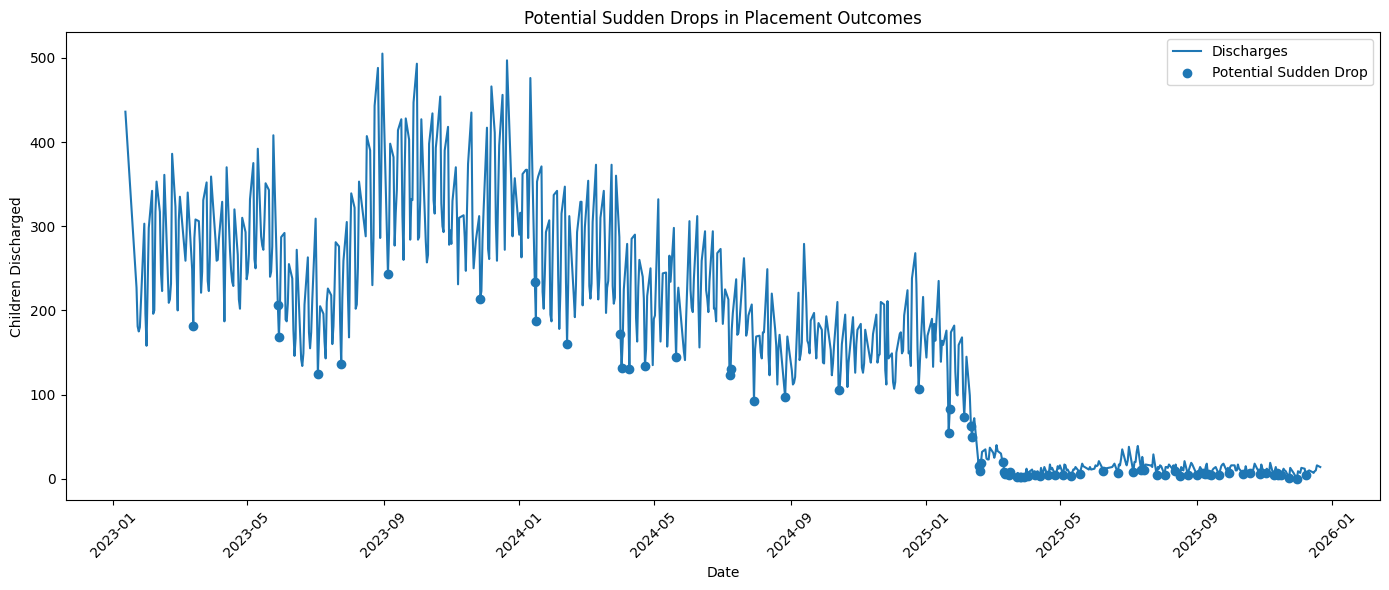

In [ ]:
# visualize sudden drops
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["discharged"],
    label="Discharges"
)

plt.scatter(
    df.loc[df["rolling_drop_flag"], "date"],
    df.loc[df["rolling_drop_flag"], "discharged"],
    label="Potential Sudden Drop"
)

plt.title("Potential Sudden Drops in Placement Outcomes")
plt.xlabel("Date")
plt.ylabel("Children Discharged")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# create an outcome stability score
# outcome stability score = (1/ 1+cv)
cv = discharge_cv

outcome_stability_score = 1 / (1 + cv)

print("Discharge CV:", cv)
print("Outcome Stability Score:", outcome_stability_score)

Discharge CV: 0.7249008450036664
Outcome Stability Score: 0.579743469253083
